In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from scipy.stats import gaussian_kde
import seaborn as sns

In [17]:
# ---------------------------------------------------------------------
# 1. STYLE - Function for style
# ---------------------------------------------------------------------

def set_publication_style():
    # sns.set_theme() RESETS matplotlib's settings, so it must run FIRST.
    # Anything set before it would be wiped out.
    sns.set_theme(context="paper", style="ticks", font_scale=1.1)

    # Now apply our own settings on top of seaborn's theme
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.0,
        "savefig.dpi": 300,
        "figure.dpi": 120,
        "pdf.fonttype": 42,     # PDF/EPS: embed TrueType fonts -> text stays editable
        "ps.fonttype": 42,
        "svg.fonttype": "none", # SVG: write text as <text> elements, NOT outlines
                                # -> Illustrator opens it as editable text
    })

# Actually RUN the function. Defining it does nothing on its own.
set_publication_style()

In [18]:
# ---------------------------------------------------------------------
# 2. RAINCLOUD PLOT - Functions for Raincloud plot (2 x 2 version)
# ---------------------------------------------------------------------
# WHAT CHANGED COMPARED TO THE 1 x N VERSION (search for "CHANGE"):
#   CHANGE 1  New LAYOUT constant: says which measure goes in which panel
#             and, row by row, which measures share a y-axis.
#   CHANGE 2  _add_significance_bars: removed the duplicate definition and
#             added a `y_ref` argument so both panels in a row place their
#             brackets at the same height.
#   CHANGE 3  raincloud_plot: new `y_ref` argument, passed straight
#             through to _add_significance_bars.
#   CHANGE 4  plot_all_measures: builds a 2 x 2 grid instead of 1 x N,
#             then forces the two panels in each row onto one y-range.
#
# Everything else (GROUP_ORDER, GROUP_COLORS, GROUP_LABELS, MEASURE_LABELS,
# RANDOM_SEED, imports) is assumed to be defined earlier in your script,
# exactly as before.
# ---------------------------------------------------------------------

# Speech measures
MEASURES = ["SWduration", "WSduration", "SWPVI", "WSPVI"]

# CHANGE 1 --------------------------------------------------------------
# LAYOUT is a list of rows; each row is a list of the measures in that row.
#   Row 1 (top):    the two duration measures  -> share one y-axis
#   Row 2 (bottom): the two PVI measures       -> share one y-axis
# Putting each "same-units" pair in its own row means that "share the
# y-axis" simply becomes "share the y-axis within a row". To change the
# panel order, or which panels share a scale, edit this list only.
LAYOUT = [
    ["SWduration", "WSduration"],   # row 0
    ["SWPVI",      "WSPVI"],        # row 1
]


def _half_violin(ax, data, position, color, width=0.4, side="upper"):
    """Draws one half of a violin (density curve) above (or to one side
    of) a given y-position, filled to the axis."""
    # (unchanged)
    if len(data) < 2:
        return
    kde = gaussian_kde(data)
    y_grid = np.linspace(data.min(), data.max(), 200)
    density = kde(y_grid)
    density = density / density.max() * width  # normalise height

    if side == "upper":
        ax.fill_betweenx(y_grid, position, position + density,
                         color=color, alpha=0.6, linewidth=0.8,
                         edgecolor=color)
    else:
        ax.fill_betweenx(y_grid, position - density, position,
                         color=color, alpha=0.6, linewidth=0.8,
                         edgecolor=color)


def raincloud_plot(df, measure, ylabel=None, title=None, ax=None,
                   stats_annotation=None, orient="vertical", y_ref=None):
    """
    One panel: half-violin density ("cloud") + boxplot + jittered raw
    points ("rain") per group, oriented vertically (groups along x).

    stats_annotation: list of (group1, group2, label_text) tuples for
    manually placed significance bars.

    y_ref: optional (y_min, y_max) tuple.                    # CHANGE 3
        If given, significance brackets are positioned relative to this
        range instead of this panel's own data. plot_all_measures passes
        the combined range of BOTH measures in a row, so the brackets sit
        at the same height in both panels of that row. If None, the panel
        behaves exactly as before (useful when plotting one panel alone).
    """
    sub = df[df["measure"] == measure]
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(5.5, 5.5))

    box_width = 0.15
    cloud_width = 0.35
    rain_offset = -0.22

    for i, g in enumerate(GROUP_ORDER):
        vals = sub.loc[sub["group"] == g, "value"].dropna().values
        color = GROUP_COLORS[g]

        # 1. Cloud (half-violin density), offset to the right of centre
        _half_violin(ax, vals, position=i + 0.02, color=color,
                     width=cloud_width, side="upper")

        # 2. Boxplot, narrow, centred
        ax.boxplot(
            vals, positions=[i], widths=box_width, vert=True,
            patch_artist=True, showfliers=False,
            boxprops=dict(facecolor="white", edgecolor=color, linewidth=1.3),
            medianprops=dict(color=color, linewidth=1.8),
            whiskerprops=dict(color=color, linewidth=1.2),
            capprops=dict(color=color, linewidth=1.2),
        )

        # 3. Rain (jittered raw points), offset to the left of centre -
        # reproduces the same every time because of RANDOM_SEED = 42
        jitter = np.random.default_rng(RANDOM_SEED + i).uniform(-0.06, 0.06, len(vals))
        ax.scatter(np.full(len(vals), i + rain_offset) + jitter, vals,
                   color=color, alpha=0.5, s=14, linewidth=0, zorder=3)

    ax.set_xlim(-0.6, len(GROUP_ORDER) - 0.3)
    ax.set_xticks(range(len(GROUP_ORDER)))
    ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in GROUP_ORDER])
    ax.set_ylabel(ylabel if ylabel else measure)
    if title:
        ax.set_title(title, fontsize=16, fontweight="bold")

    if stats_annotation:
        # CHANGE 3: pass y_ref through to the bracket function
        _add_significance_bars(ax, sub, stats_annotation, y_ref=y_ref)

    if own_fig:
        fig.tight_layout()
        return fig, ax
    return ax


# CHANGE 2 --------------------------------------------------------------
# Your original file defined _add_significance_bars TWICE. Python silently
# keeps only the LAST definition, so the first one (fontsize=32) was never
# used. There is now a single definition.
def _add_significance_bars(ax, sub, comparisons, y_ref=None):
    """
    Draws brackets + labels for each (group1, group2, label) comparison,
    stacking them upwards above the data.

    y_ref: optional (y_min, y_max). If given, bracket heights are based on
    this range rather than on this panel's own data (see raincloud_plot).
    """
    if y_ref is None:
        y_min, y_max = sub["value"].min(), sub["value"].max()
    else:
        y_min, y_max = y_ref
    y_range = y_max - y_min
    step = y_range * 0.14            # vertical gap between stacked brackets
    current_y = y_max + step * 0.6   # first bracket starts just above the data

    for g1, g2, label in comparisons:
        x1, x2 = GROUP_ORDER.index(g1), GROUP_ORDER.index(g2)
        ax.plot([x1, x1, x2, x2],
                [current_y, current_y + step * 0.15,
                 current_y + step * 0.15, current_y],
                lw=1.2, color="black")
        ax.text((x1 + x2) / 2, current_y + step * 0.2, label,
                ha="center", va="bottom", fontsize=24)
        current_y += step

    # Guarantee a visible gap above the last bracket.
    # (The old `ax.margins(y=0.05)` line was removed: once set_ylim has been
    # called, matplotlib stops autoscaling that axis, so margins() had no
    # effect.)
    ax.set_ylim(top=current_y + step * 0.5)


# CHANGE 4 --------------------------------------------------------------
def plot_all_measures(df, sig_annotations=None, layout=LAYOUT):
    """
    Draws one raincloud panel per measure on a grid defined by `layout`
    (2 x 2 by default). All panels in the same row share one y-axis range.
    """
    sig_annotations = sig_annotations or {}

    # 4a. Grid size comes from LAYOUT: 2 rows x 2 columns.
    n_rows = len(layout)
    n_cols = max(len(row) for row in layout)

    # 4b. Figure size scales with the grid: each panel keeps roughly the
    #     same 5.2 x 5.5 inch footprint it had in the 1 x N version.
    #     squeeze=False guarantees `axes` is always a 2-D array, so we can
    #     always index it as axes[row, col].
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(5.2 * n_cols, 5.5 * n_rows),
                             squeeze=False)

    for r, row_measures in enumerate(layout):

        # 4c. Combined data range for the whole row (e.g. SWduration AND
        #     WSduration together). Passed as y_ref so significance brackets
        #     start at the same height in both panels.
        row_vals = df.loc[df["measure"].isin(row_measures), "value"].dropna()
        y_ref = (row_vals.min(), row_vals.max())

        # 4d. Draw each panel in this row.
        for c, measure in enumerate(row_measures):
            raincloud_plot(df, measure,
                           ylabel=MEASURE_LABELS.get(measure, measure),
                           title=MEASURE_LABELS.get(measure, measure).split(" (")[0],
                           ax=axes[r, c],
                           stats_annotation=sig_annotations.get(measure),
                           y_ref=y_ref)

        # 4e. Force identical y-limits across the row. Each panel has already
        #     chosen its own limits (from its data and its brackets); we take
        #     the lowest bottom and highest top across the row and apply them
        #     to every panel, so nothing gets clipped and the scales match.
        row_axes = axes[r, :len(row_measures)]
        bottom = min(a.get_ylim()[0] for a in row_axes)
        top = max(a.get_ylim()[1] for a in row_axes)
        for a in row_axes:
            a.set_ylim(bottom, top)

        # 4f. If a row has fewer measures than columns, hide empty panels.
        for c in range(len(row_measures), n_cols):
            axes[r, c].set_visible(False)

    fig.tight_layout()
    return fig, axes


In [ ]:
# df = pd.read_excel("your_data_file.xlsx")
# read participant data here

In [7]:
## filter for baseline to plot speech measures
baseline_df = df[df["Timepoint "] == 1]
baseline_df["PID"].value_counts().loc[lambda s: s > 1] # check that no one is counted twice


Series([], Name: count, dtype: int64)

In [10]:
# ---------------------------------------------------------------------
# 0. CONFIG
# ---------------------------------------------------------------------

DATA_PATH = '/path/to/project.folder' # put data folder here
OUTPUT_DIR = "Figures"
RANDOM_SEED = 42 # fixes jitter positions in raincloud plots so figures are identical on rerun

GROUP_ORDER = ["Control", "PNFA", "Logopenic"]
GROUP_LABELS = {
    "Control": "HC",
    "PNFA": "nfvPPA",
    "Logopenic": "lvPPA"
}
GROUP_COLORS = {
    "Control":     "#4C72B0",
    "PNFA": "#DD8452",
    "Logopenic":  "#55A868",
}

# Speech measures 
MEASURES = ["SWduration", "WSduration", "SWPVI", "WSPVI" ]
MEASURE_LABELS = {
    "SWduration":  "SW duration (ms)",
    "WSduration": "WS duration (ms)",
    "SWPVI":      "SW PVI",
    "WSPVI":     "WS PVI",
}

os.makedirs(OUTPUT_DIR, exist_ok=True)



In [ ]:
long_df_sp_bs = baseline_df.melt(
    id_vars=["PID", "SummaryPrimaryDiagnosis"],
    value_vars=MEASURES,
    var_name="measure",
    value_name="value",
)
long_df_sp_bs = long_df_sp_bs.rename(columns={"SummaryPrimaryDiagnosis": "group"}) #important to rename for the raincloud plot function below
long_df_sp_bs # long format df for plotting of baseline speech measures across groups

In [12]:
SIG_ANNOTATIONS = {
    "SWduration": [("Control", "PNFA", "***"),
                  ("Logopenic", "PNFA", "*")],
    "WSduration": [("Control", "PNFA", "***"),
                   ("Logopenic", "PNFA", "***")],
}

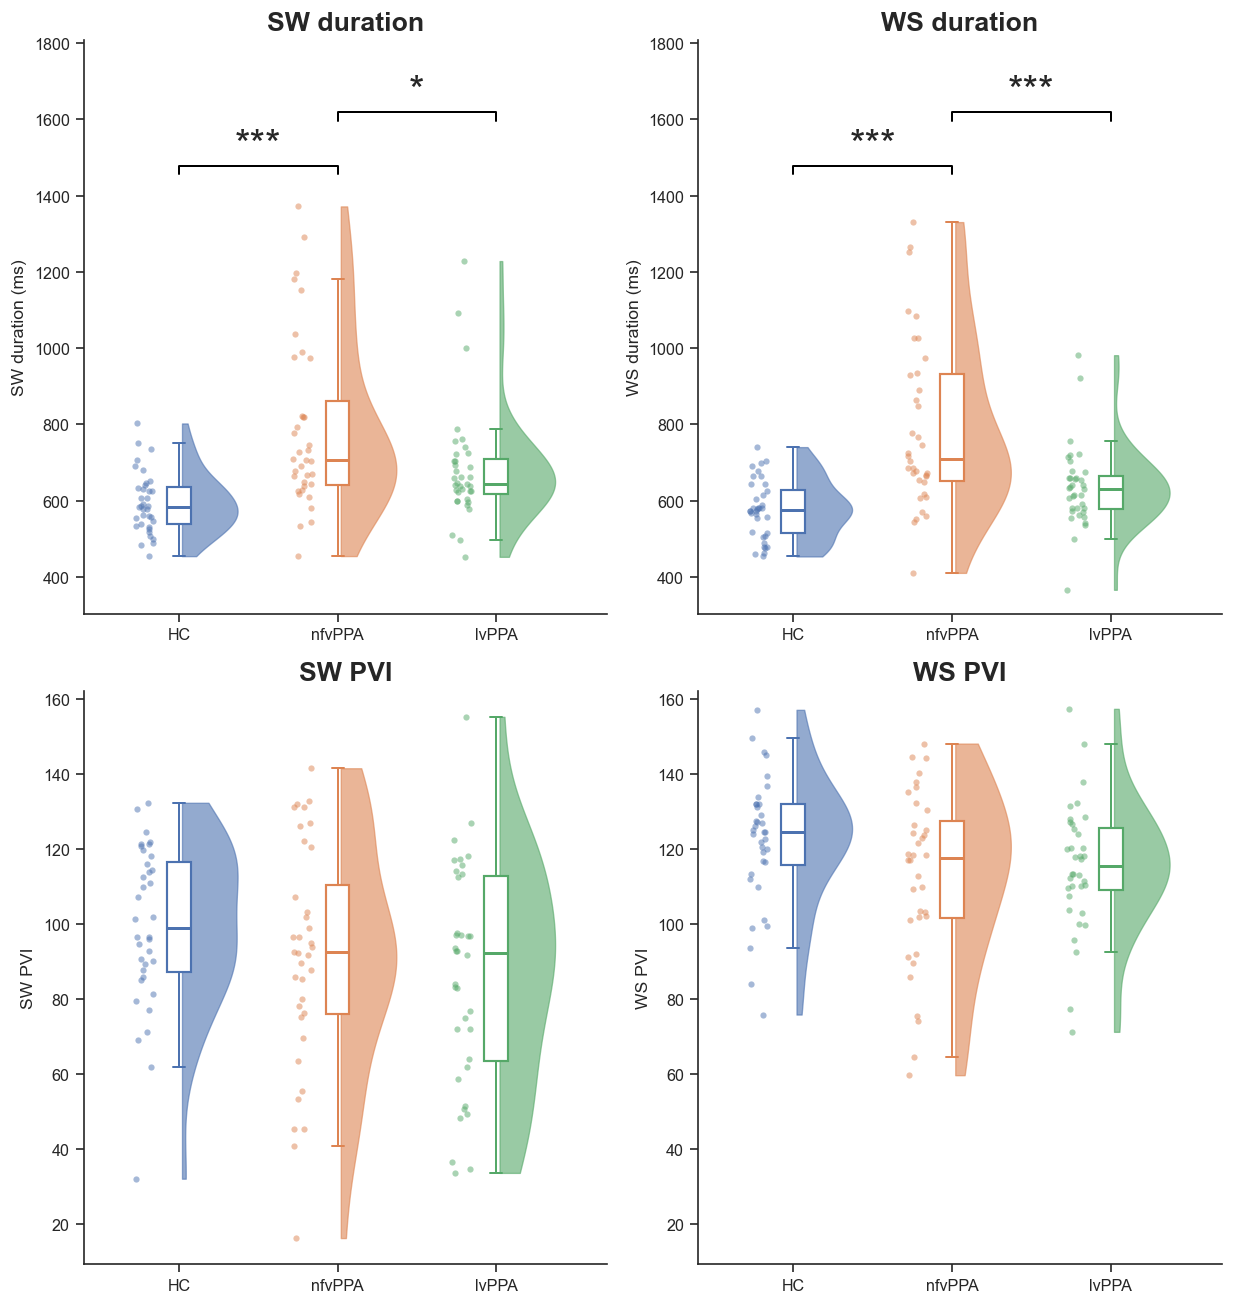

In [19]:
fig, axes = plot_all_measures(long_df_sp_bs, sig_annotations=SIG_ANNOTATIONS)

#fig, axes = plot_all_measures(long_df_sp_bs)
fig.savefig(os.path.join(OUTPUT_DIR, "Figure_2.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUTPUT_DIR, "Figure_2.png"), bbox_inches="tight")
fig.savefig(os.path.join(OUTPUT_DIR, "Figure_2.svg"), bbox_inches="tight")
plt.show()